# ORIE 5355 Project 2026: Part 1 capacity-constrained pricing


Run `model_training/purchase_model_baseline.ipynb` first; it saves the model loaded by `agents/agent_part1.py`. Our  naive implemented agent chooses prices using predicted purchase probabilities, with a simple inventory-conservation heuristic -- you should replace it with your better strategies.

Inventory is a uniformly random integer from 7 to 20 every 20 customers.

Use `run_project_part1_static_2026.ipynb` for unconstrained static pricing, and `run_project_part2_2026.ipynb` for Part 2 competition. Complete both Part 1 tasks.


In [1]:
from pathlib import Path
import os
import sys

# Resolve paths once so every notebook uses the project folder.
project_folder = next((
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / 'project_code_2026_publicshare',
                   parent / 'project_2026/project_code_2026_publicshare',
                   parent / 'private_github/project_2026/project_code_2026_publicshare')
    if (folder / 'pricing_helpers.py').is_file()
), None)
if project_folder is None:
    raise FileNotFoundError('Open the project folder as your notebook workspace.')
os.chdir(project_folder)
sys.path.insert(0, str(project_folder))

import copy
import numpy as np 
import matplotlib.pyplot as plt
import time
from IPython import display

In [2]:
import make_env_2026 as make_env

### Part 1: capacity extension

In [3]:
# In part 1, each team's agent will be evaluated alone.
project_part = 1
agentnames = ['agent_part1']

In [4]:
env, agents = make_env.make_env_agents(
    agentnames = agentnames, 
    project_part = project_part, 
    first_file = 'data/datafile1_2026.csv', 
    second_file='data/datafile2_2026.csv'
    )

# you can replace the agentnames to match whatever agentfiles you create. 
# Do not rename agents/agent_part1.py or the agents/helper_files_here/ folder.

In [12]:
T = 500 #2500
verbose = False

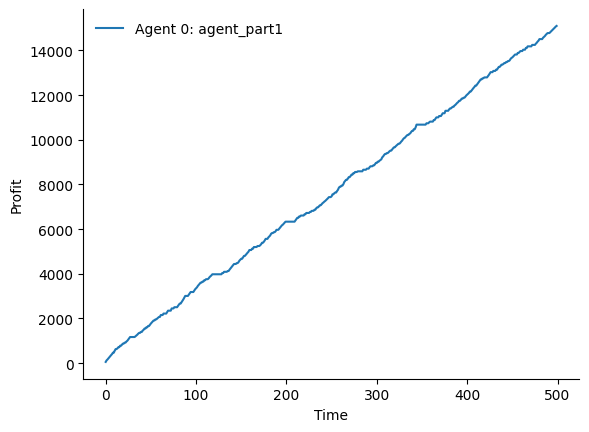

Cumulative profit: [15100.0]
Average revenue per customer: [30.2]
Cumulative buyer utility: [10176.91565505]


In [13]:
env.reset()
customer_covariates, sale, profits, inventories, time_until_replenish = env.get_current_state_customer_to_send_agents()
last_customer_covariates = customer_covariates
inventory_history = []

fig, ax = plt.subplots(figsize=(20, 10))
for t in range(0, T):
    actions = [agent.action(copy.deepcopy((customer_covariates, sale, profits, inventories, time_until_replenish))) for agent in agents]
    customer_covariates, sale, profits, inventories, time_until_replenish = env.step(actions)
    inventory_history.append(inventories[0])
    newplot = env.render(True)
    if newplot:
        display.clear_output(wait=True)
        display.display(plt.gcf())
    if verbose:
        print('last customer covariate: ', last_customer_covariates)
        print('last (item bought, agent bought from, prices): ', sale)
        print('current_profit per agent: ', profits)
    last_customer_covariates = customer_covariates

plt.close()
print("Cumulative profit: {}".format(env.agent_profits))
print("Average revenue per customer: {}".format(np.asarray(env.agent_profits)/T))
print("Cumulative buyer utility: {}".format(env.cumulative_buyer_utility))

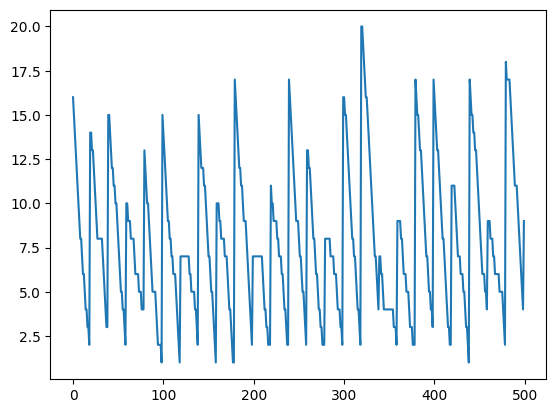

In [15]:
plt.plot(inventory_history)

# Value Table SETUP

In [ ]:
import pandas as pd
import pickle

with (project_folder / 'agents/helper_files_here/purchase_model1.pkl').open('rb') as file:
    model = pickle.load(file)  # Only load pickle files you trust.

price_grid = np.linspace(0, 500, 101) #THIS NEEDS TO BE THE SAME AS IN AGENT_PART1.PY, OTHERWISE THE VALUE TABLE WILL NOT WORK. IMPORTANTTT


In [ ]:
historic_data = pd.read_csv(project_folder / 'data/train_prices_decisions_2026.csv')
customers = historic_data[['Covariate1', 'Covariate2', 'Covariate3']].to_numpy()
features = pd.DataFrame( 
    np.repeat(customers, len(price_grid), axis=0),
    columns=['Covariate1', 'Covariate2', 'Covariate3']
)
features['price_item'] = np.tile(price_grid, len(customers))
historical_predictions = np.clip(np.array(model.predict(features)), 0, 1).reshape(len(customers), len(price_grid))

In [10]:
def get_single_2dstep_revenue_maximizing_price_and_revenue(Vtplus1_k_minus_1, Vtplus1_k, price_options, demand_predictions):
    p = np.array(price_options)
    d = np.array(demand_predictions)

    expected_revenue = d * (p + Vtplus1_k_minus_1) + (1 - d) * Vtplus1_k
    idx = np.argmax(expected_revenue)

    return float(p[idx]), float(expected_revenue[idx])

In [25]:
def build_value_table(prices, demand_predictions, T, K):
    """
    Build V using historical customers.
    demand_predictions shape: (number_of_customers, number_of_prices)
    V[t, k]: expected future revenue with t rounds elapsed and k items.
    """
    V = np.zeros((T + 1, K + 1))

    for t in range(T - 1, -1, -1):
        for k in range(1, K + 1):
            expected_revenue = (demand_predictions * (prices + V[t + 1, k - 1]) + (1 - demand_predictions) * V[t + 1, k])      # Gets expected rev for each customer and each price in price grid
            # Best price for EACH customer, then average their values.
            best_customer_values = np.max(expected_revenue, axis=1)
            V[t, k] = np.mean(best_customer_values)
    return V

In [32]:
V = build_value_table(
    price_grid,
    historical_predictions,
    T=21,
    K=21
)

In [34]:
model_path = project_folder / 'agents/helper_files_here/value_table.pkl'
with model_path.open('wb') as file:
    pickle.dump(V, file)

save_path = project_folder / 'agents/helper_files_here/historical_predictions.pkl'
with open(save_path, 'wb') as file:
    pickle.dump(historical_predictions, file)

## Short Example

In [ ]:
env.reset()
customer_covariates, sale, profits, inventories, time_until_replenish = env.get_current_state_customer_to_send_agents()
actions = [agent.action(copy.deepcopy((customer_covariates, sale, profits, inventories, time_until_replenish ))) for agent in agents]
features = pd.DataFrame(np.tile(customer_covariates, (len(price_grid), 1)),
                                columns=['Covariate1', 'Covariate2', 'Covariate3'])
features['price_item'] = price_grid

t = 2
k = 4

features = pd.DataFrame(np.tile(customer_covariates, (len(price_grid), 1)),
                                columns=['Covariate1', 'Covariate2', 'Covariate3'])
features['price_item'] = price_grid
probability = np.clip(model.predict(features), 0, 1)
price, _ = get_single_2dstep_revenue_maximizing_price_and_revenue(V[t + 1, k - 1], V[t + 1, k],price_grid, probability)
price

80.0

In [ ]:
@staticmethod
def build_value_table(prices, demand_predictions, T, K):
    """
    Build V using historical customers.
    demand_predictions shape: (number_of_customers, number_of_prices)
    V[t, k]: expected future revenue with t rounds elapsed and k items.
    """
    V = np.zeros((T + 1, K + 1))
    for t in range(T - 1, -1, -1):
        for k in range(1, K + 1):
            expected_revenue = (demand_predictions * (prices + V[t + 1, k - 1]) + (1 - demand_predictions) * V[t + 1, k])   
            # Gets expected rev for each customer and each price in price grid
            # Best price for EACH customer, then average their values.
            best_customer_values = np.max(expected_revenue, axis=1)
            V[t, k] = np.mean(best_customer_values)
    return V